<a href="https://colab.research.google.com/github/wajihabibi/RhombixTechnologies_Tasks/blob/main/Titanic_Survival_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

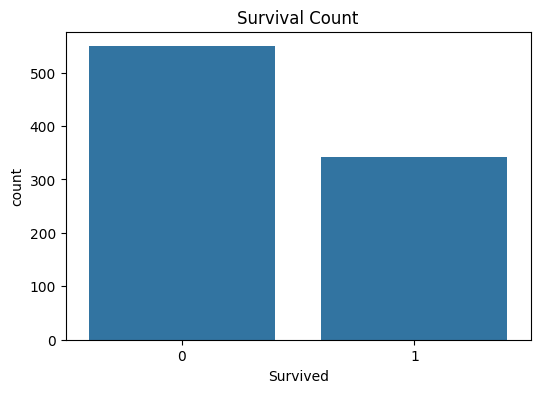

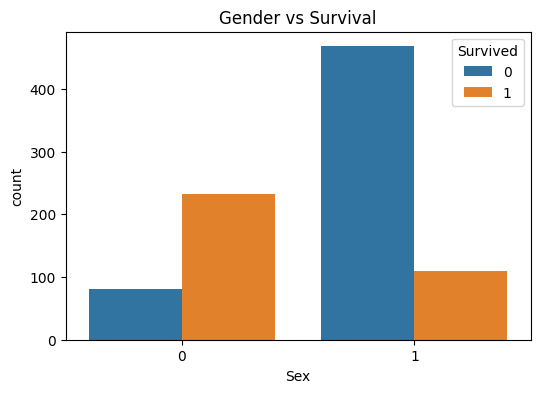

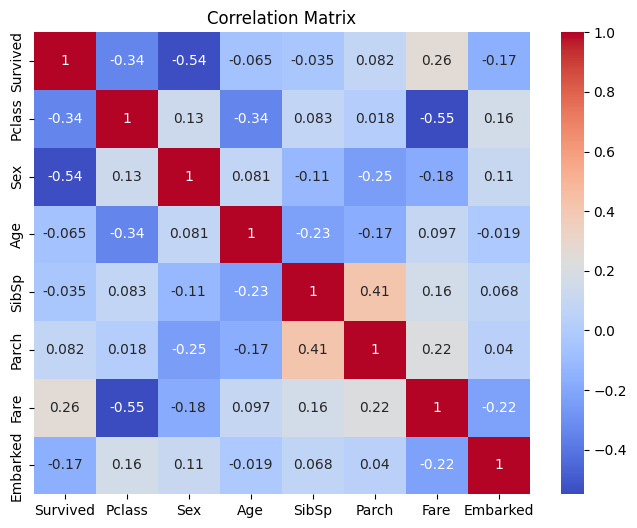


Accuracy: 0.8212290502793296

Confusion Matrix
[[92 13]
 [19 55]]


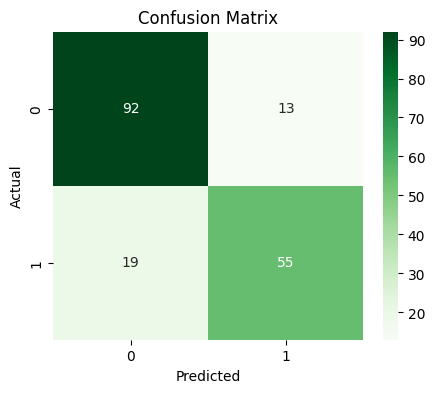


Classification Report
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179


Feature Importance
    Feature  Importance
1       Sex    0.271410
5      Fare    0.265010
2       Age    0.249995
0    Pclass    0.086957
3     SibSp    0.053685
4     Parch    0.039897
6  Embarked    0.033044


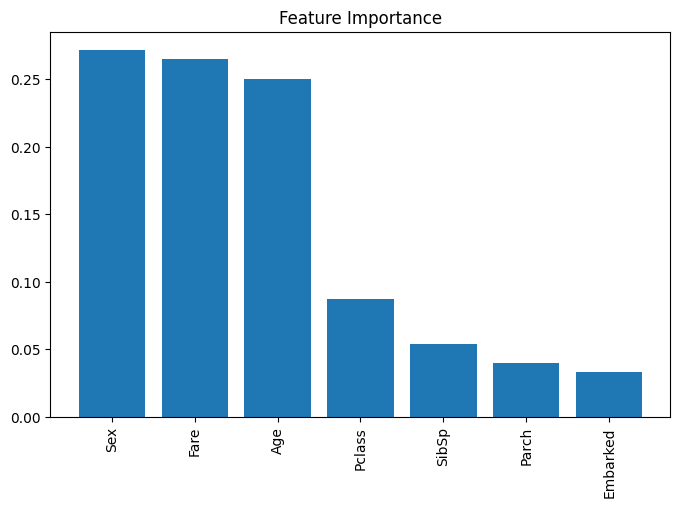

Passenger is likely to SURVIVE.


In [63]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


# Load Dataset
df=pd.read_csv("train.csv")
print(df)
# Check Information
print(df.info())

# Check Null Values
print(df.isnull().sum())

# Fill Missing Values
df["Age"]=df["Age"].fillna(df["Age"].median())
df["Embarked"]=df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Cabin"]=df["Cabin"].fillna(df["Cabin"].mode()[0])
print(df)


# drop unnecessary columns
df.drop(["PassengerId","Name","Cabin","Ticket"],axis=1,inplace=True)
print(df)

# Convert Catagorial Data into Numbers
le=LabelEncoder()
df['Sex']=le.fit_transform(df['Sex'])
df['Embarked']=le.fit_transform(df['Embarked'])

# display cleaned Data
print(df.head())

# Feature Selection


X = df.drop("Survived", axis=1)
y = df["Survived"]

# Split Dataset

X_train, X_test, y_train, y_test = train_test_split( X,
    y,
    test_size=0.20,
    random_state=42)
print("Train Data")
print(X_train)
print("Test Data")
print(X_test)
print("Train Data")
print(y_train)
print("Test Data")
print(y_test)

# Data Visualization

plt.figure(figsize=(6,4))
sns.countplot(x="Survived", data=df)
plt.title("Survival Count")
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x="Sex", hue="Survived", data=df)
plt.title("Gender vs Survival")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# Train Random Forest Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Prediction
predictions = model.predict(X_test)

# Accuracy
accur = accuracy_score(y_test, predictions)

print("\nAccuracy:", accur)

# Confusion Matrix
cm = confusion_matrix(y_test, predictions)
print("\nConfusion Matrix")
print(cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("\nClassification Report")
print(classification_report(y_test, predictions))

# Feature Importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)

print("\nFeature Importance")
print(importance)

plt.figure(figsize=(8,5))
plt.bar(importance["Feature"], importance["Importance"])
plt.title("Feature Importance")
plt.xticks(rotation=90)
plt.show()

# Predict a New Passenger
# Format:
# Pclass, Sex, Age, SibSp, Parch, Fare, Embarked

# Sex:
# Male = 1
# Female = 0

# Embarked:
# C = 0
# Q = 1
# S = 2



new_passenger = pd.DataFrame({
    "Pclass": [1],
    "Sex": [0],
    "Age": [25],
    "SibSp": [0],
    "Parch": [0],
    "Fare": [100],
    "Embarked": [2]
})

prediction = model.predict(new_passenger)

# print Predictions

if prediction[0] == 1:
    print("Passenger is likely to SURVIVE.")
else:
    print("Passenger is NOT likely to SURVIVE.")
